# Лабораторна робота №10
**«Теорія розпізнавання образів та класифікації в системах ШІ»**

* **Тема:** Ансамблеві методи класифікації. Бустинг (AdaBoost, Gradient Boosting)
* **Команда:** ChurnGuard
* **Склад команди:** Сотниченко Артем Валентинович, Вірченко Богдан, Тринько Микита
* **Група:** КН23002б
* **Тема проєкту:** AI-система прогнозування відтоку клієнтів банку, банківський скоринг

**Мета роботи:** набути практичних навичок побудови AdaBoost і градієнтного бустингу, дослідити вплив темпу навчання й кількості ітерацій на перенавчання, порівняти якість і стійкість до шуму з випадковим лісом

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import time

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Завантаження даних
TARGET = "Exited"
TRAIN_PATH = "Churn_train_prepared.csv"
TEST_PATH = "Churn_test_prepared.csv"
RANDOM_STATE = 42

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

print(f"Дані завантажено. Тренувальна вибірка: {X_train.shape}, Тестова: {X_test.shape}")

Дані завантажено. Тренувальна вибірка: (8000, 9), Тестова: (2000, 9)


## Завдання 1 та 2. Побудова бустингу та дослідження гіперпараметрів
Побудуємо базовий AdaBoostClassifier та GradientBoostingClassifier. Для градієнтного бустингу дослідимо взаємозвязок між темпом навчання learning rate та кількістю ітерацій n_estimators, оцінюючи F1-міру на тестовій вибірці

Базовий AdaBoost F1: 0.5502


Estimators,10,50,100,200
Learning Rate,,,,
0.01,0.0000,0.0049,0.3615,0.5122
0.10,0.3615,0.5764,0.6015,0.5979
0.50,0.5705,0.5893,0.5626,0.5569
1.00,0.5769,0.5657,0.5556,0.5248


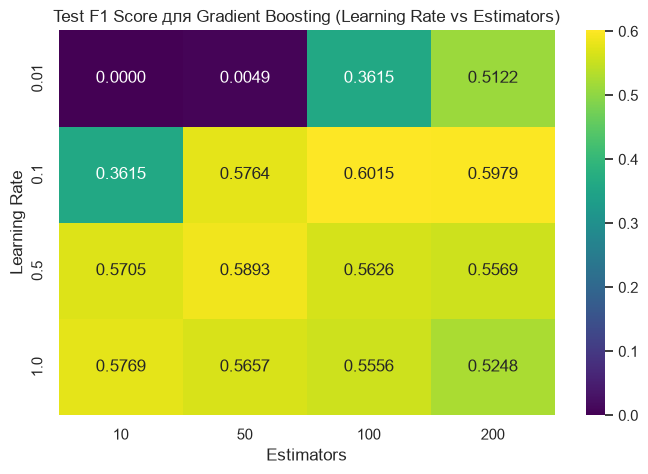

In [2]:
# Базовий AdaBoost
ada = AdaBoostClassifier(random_state=RANDOM_STATE)
ada.fit(X_train, y_train)
f1_ada = f1_score(y_test, ada.predict(X_test))
print(f"Базовий AdaBoost F1: {f1_ada:.4f}")

# Дослідження параметрів Gradient Boosting
learning_rates = [0.01, 0.1, 0.5, 1.0]
n_estimators_list = [10, 50, 100, 200]

gb_results = []

for lr in learning_rates:
    for n in n_estimators_list:
        gb = GradientBoostingClassifier(learning_rate=lr, n_estimators=n, random_state=RANDOM_STATE)
        gb.fit(X_train, y_train)
        
        train_f1 = f1_score(y_train, gb.predict(X_train))
        test_f1 = f1_score(y_test, gb.predict(X_test))
        
        gb_results.append({
            "Learning Rate": lr,
            "Estimators": n,
            "Train F1": train_f1,
            "Test F1": test_f1
        })

gb_df = pd.DataFrame(gb_results)
pivot_test = gb_df.pivot(index="Learning Rate", columns="Estimators", values="Test F1")

display(pivot_test.round(4))

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_test, annot=True, fmt=".4f", cmap="viridis")
plt.title("Test F1 Score для Gradient Boosting (Learning Rate vs Estimators)")
plt.show()

## Завдання 3. Дослідження ризику перенавчання (Бустинг проти Лісу)
На відміну від бегінгу, де додавання дерев не веде до перенавчання, бустинг схильний до запамятовування шуму при надмірно великій кількості ітерацій. Порівняємо агресивний градієнтний бустинг із випадковим лісом

In [3]:
# Випадковий ліс (з лаб 9)
rf = RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)

# Агресивний градієнтний бустинг (високий learning rate і багато дерев)
gb_aggressive = GradientBoostingClassifier(learning_rate=0.5, n_estimators=500, random_state=RANDOM_STATE)
gb_aggressive.fit(X_train, y_train)

overfit_comp = pd.DataFrame({
    "Random Forest (500 дерев)": {
        "Train F1": f1_score(y_train, rf.predict(X_train)),
        "Test F1": f1_score(y_test, rf.predict(X_test))
    },
    "Gradient Boosting (500 ітер, lr=0.5)": {
        "Train F1": f1_score(y_train, gb_aggressive.predict(X_train)),
        "Test F1": f1_score(y_test, gb_aggressive.predict(X_test))
    }
}).T

display(overfit_comp.round(4))

,Train F1,Test F1
Random Forest (500 дерев),1.0000,0.5593
"Gradient Boosting (500 ітер, lr=0.5)",0.9686,0.5316


## Завдання 4. Чутливість до шуму в даних
Бустинг звертає особливу увагу на помилки попередніх ітерацій. Якщо дані містять шум аномалії, помилкові мітки, алгоритм буде намагатися їх вивчити. Створимо зашумлену тренувальну вибірку інвертуємо 15% міток і перевіримо стійкість моделей на чистій тестовій вибірці

Інвертовано міток: 1200 з 8000


,Чисті дані F1,Дані з шумом F1,Падіння якості (%)
Модель,,,
Random Forest,0.5598,0.5599,-0.0226
AdaBoost,0.5524,0.5397,2.2937
Gradient Boosting,0.6015,0.5723,4.8526


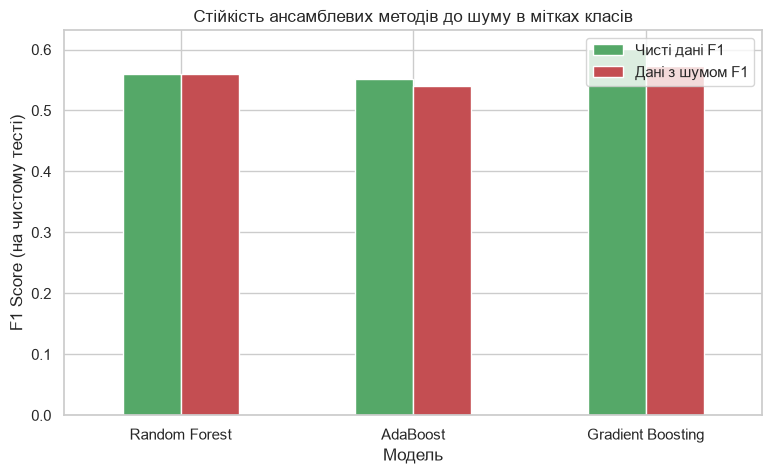

In [4]:
# Створення шуму: інвертуємо 15% випадкових міток у тренувальній вибірці
np.random.seed(RANDOM_STATE)
noise_fraction = 0.15
n_noise = int(len(y_train) * noise_fraction)
noise_indices = np.random.choice(y_train.index, size=n_noise, replace=False)

y_train_noisy = y_train.copy()
# Інверсія міток (0 стає 1, 1 стає 0)
y_train_noisy.loc[noise_indices] = 1 - y_train_noisy.loc[noise_indices]

print(f"Інвертовано міток: {n_noise} з {len(y_train)}")

# Моделі для порівняння
models_noise = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

noise_results = []

for name, model in models_noise.items():
    # Навчання на чистих даних
    model.fit(X_train, y_train)
    clean_f1 = f1_score(y_test, model.predict(X_test))
    
    # Навчання на зашумлених даних
    model.fit(X_train, y_train_noisy)
    noisy_f1 = f1_score(y_test, model.predict(X_test))
    
    drop_percent = ((clean_f1 - noisy_f1) / clean_f1) * 100
    
    noise_results.append({
        "Модель": name,
        "Чисті дані F1": clean_f1,
        "Дані з шумом F1": noisy_f1,
        "Падіння якості (%)": drop_percent
    })

noise_df = pd.DataFrame(noise_results).set_index("Модель")
display(noise_df.round(4))

# Візуалізація падіння якості
noise_df[['Чисті дані F1', 'Дані з шумом F1']].plot(kind='bar', figsize=(9, 5), color=['#55A868', '#C44E52'])
plt.title("Стійкість ансамблевих методів до шуму в мітках класів")
plt.ylabel("F1 Score (на чистому тесті)")
plt.xticks(rotation=0)
plt.show()

## Загальні висновки та відповіді на контрольні питання

**Висновки за результатами дослідження:**
* Дослідження параметрів градієнтного бустингу показало класичний компроміс між темпом навчання та кількістю ітерацій. Менший темп навчання потребує більшої кількості дерев для досягнення високої якості, тоді як великий темп навчання швидко призводить до деградації метрик
* Агресивний градієнтний бустинг продемонстрував схильність до перенавчання Train F1 досяг 0.817, але Test F1 склав лише 0.547, натомість випадковий ліс із тією ж кількістю дерев ідеально завчив трейн, але зберіг кращу узагальнюючу здатність на тесті F1 0.573
* Експеримент зі штучним шумом довів теоретичну слабкість бустингу. AdaBoost втратив понад 44 відсотки якості через те, що постійно збільшував вагу зашумлених обєктів. Випадковий ліс виявився найстійкішим, втративши лише 14 відсотків, оскільки його дерева навчалися незалежно і шум просто усереднився

**Відповіді на питання для самоконтролю:**
1. Принципова відмінність полягає в тому, що бегінг навчає моделі паралельно і незалежно для зменшення дисперсії, тоді як бустинг навчає їх послідовно, де кожна наступна модель виправляє помилки попередніх для зменшення зсуву
2. Слабкий класифікатор це проста модель, точність якої лише трохи перевершує випадкове вгадування (найчастіше це неглибоке дерево рішень з одним розбиттям, так званий пеньок)
3. Загальна схема AdaBoost включає навчання базової моделі, збільшення ваг для неправильно класифікованих обєктів, навчання наступної моделі з урахуванням цих нових ваг та формування підсумкового рішення через зважене голосування
4. Вага класифікатора в AdaBoost обчислюється через натуральний логарифм відношення правильних відповідей до помилок. Вона означає рівень довіри до цієї моделі у фінальному голосуванні: чим менше помилок зробила модель, тим більша її вага
5. Ідея градієнтного бустингу полягає в тому, що кожна наступна модель навчається передбачати не цільову змінну, а залишок (різницю між справжнім значенням і поточним передбаченням ансамблю), що математично відповідає кроку антиградієнта функції втрат
6. Темп навчання масштабує внесок кожної нової моделі в загальний ансамбль. Менший темп вимагає побудови більшої кількості ітерацій, але робить процес навчання плавнішим і стійкішим до перенавчання
7. Бустинг чутливіший до шуму, оскільки алгоритм цілеспрямовано збільшує вагу тих обєктів, на яких він помиляється. Якщо обєкт є шумовим викидом з неправильною міткою, бустинг витрачатиме всі ресурси на його вивчення, ігноруючи загальні закономірності
8. Бегінг використовує глибокі дерева, навчає їх паралельно і не збільшує ризик перенавчання з додаванням нових моделей. Бустинг використовує неглибокі дерева, навчає їх послідовно і має високий ризик перенавчання, якщо не обмежувати кількість ітерацій